# **Import Libraries**

In [53]:
BASE_PATH = "/Users/alvinsaju/Desktop/DISSERTATION/Predicting Urban Traffic Congestion Patterns" 

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf

In [55]:
df_aug = pd.read_csv(f"{BASE_PATH}/DATASET/SCATSAugust2025.csv")

# **Data Preprocessing**

In [56]:
df_aug.head()

,End_Time,Region,Site,Detector,Sum_Volume,Avg_Volume,Weighted_Avg,Weighted_Var,Weighted_Std_Dev
0,20250826000000,SCITY,1009,11.0,0.0,0.0,NaN,NaN,NaN
1,20250826000000,SCITY,1009,12.0,0.0,0.0,NaN,NaN,NaN
2,20250826000000,SCITY,1009,13.0,0.0,0.0,NaN,NaN,NaN
3,20250826000000,SCITY,1009,14.0,0.0,0.0,NaN,NaN,NaN
4,20250826000000,SCITY,1009,15.0,0.0,0.0,NaN,NaN,NaN


In [57]:
df_aug.tail()

,End_Time,Region,Site,Detector,Sum_Volume,Avg_Volume,Weighted_Avg,Weighted_Var,Weighted_Std_Dev
10788602,20250818210000,IRE3,5123,12.0,0.0,0.0,NaN,NaN,NaN
10788603,20250818210000,IRE3,5123,13.0,3.0,0.0,NaN,NaN,NaN
10788604,20250818210000,IRE3,5123,14.0,7.0,0.0,NaN,NaN,NaN
10788605,20250818210000,IRE3,5123,15.0,12.0,1.0,NaN,NaN,NaN
10788606,20250818210000,IRE3,512,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
df_aug.shape

(10788607, 9)

In [59]:
df_aug.columns

Index(['End_Time', 'Region', 'Site', 'Detector', 'Sum_Volume', 'Avg_Volume',
       'Weighted_Avg', 'Weighted_Var', 'Weighted_Std_Dev'],
      dtype='object')

In [60]:
df_aug = df_aug.drop(columns=['Weighted_Avg', 'Weighted_Var', 'Weighted_Std_Dev'])

In [61]:
df_aug.describe()

,End_Time,Site,Detector,Sum_Volume,Avg_Volume
count,1.078861e+07,1.078861e+07,1.078861e+07,1.078861e+07,1.078861e+07
mean,2.025082e+13,2.238751e+03,1.148322e+01,4.120677e+01,3.297726e+00
std,8.946925e+06,2.553455e+03,7.619442e+00,1.027571e+02,8.556977e+00
min,2.025080e+13,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.025081e+13,3.230000e+02,5.000000e+00,0.000000e+00,0.000000e+00
50%,2.025082e+13,7.610000e+02,1.000000e+01,0.000000e+00,0.000000e+00
75%,2.025082e+13,5.137000e+03,1.800000e+01,1.900000e+01,1.000000e+00
max,2.025083e+13,9.998000e+03,3.100000e+01,3.035000e+03,5.020000e+02


In [62]:
df_aug.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10788607 entries, 0 to 10788606
Data columns (total 6 columns):
 #   Column      Dtype  
---  ------      -----  
 0   End_Time    int64  
 1   Region      object 
 2   Site        int64  
 3   Detector    float64
 4   Sum_Volume  float64
 5   Avg_Volume  float64
dtypes: float64(3), int64(2), object(1)
memory usage: 493.9+ MB


In [63]:
df_aug.dtypes

End_Time        int64
Region         object
Site            int64
Detector      float64
Sum_Volume    float64
Avg_Volume    float64
dtype: object

In [64]:
df_aug = df_aug.dropna()

In [65]:
df_aug.isnull().sum()

End_Time      0
Region        0
Site          0
Detector      0
Sum_Volume    0
Avg_Volume    0
dtype: int64

In [66]:
df_aug['End_Time'] = pd.to_datetime(df_aug['End_Time'].astype(str), format='%Y%m%d%H%M%S')
df_aug = df_aug.sort_values('End_Time')

# **Feature Engineering**

In [67]:
df_aug['Hour'] = df_aug['End_Time'].dt.hour
df_aug['Day'] = df_aug['End_Time'].dt.dayofweek
df_aug['Peak_Hour'] = df_aug['Hour'].apply(
    lambda x: 1 if (7 <= x <= 10 or 16 <= x <= 19) else 0
)

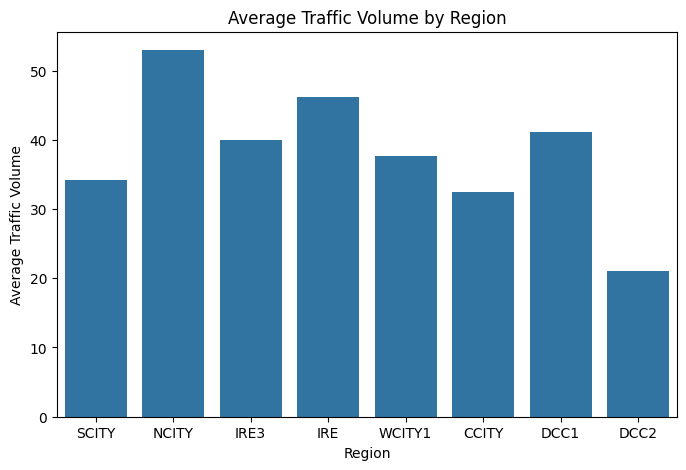

In [68]:
plt.figure(figsize=(8,5))
sns.barplot(
    x='Region',
    y='Sum_Volume',
    data=df_aug,
    estimator=np.mean,
    errorbar=None
)
plt.title("Average Traffic Volume by Region")
plt.xlabel("Region")
plt.ylabel("Average Traffic Volume")
plt.show()

In [69]:
le = LabelEncoder()
df_aug['Region'] = le.fit_transform(df_aug['Region'])

In [70]:
df_aug.corr()

,End_Time,Region,Site,Detector,Sum_Volume,Avg_Volume,Hour,Day,Peak_Hour
End_Time,1.000000,-0.001816,-0.007197,-0.003079,0.024233,0.025543,0.047326,0.017717,0.008381
Region,-0.001816,1.000000,-0.192129,-0.047011,0.011369,0.013513,0.000564,0.001398,0.001367
Site,-0.007197,-0.192129,1.000000,0.012076,0.028708,0.026316,0.000410,0.000220,0.000450
Detector,-0.003079,-0.047011,0.012076,1.000000,-0.380112,-0.369810,-0.000136,-0.000022,-0.000122
Sum_Volume,0.024233,0.011369,0.028708,-0.380112,1.000000,0.993705,0.137279,-0.018612,0.086589
Avg_Volume,0.025543,0.013513,0.026316,-0.369810,0.993705,1.000000,0.136935,-0.018373,0.086096
Hour,0.047326,0.000564,0.000410,-0.000136,0.137279,0.136935,1.000000,0.003780,0.148260
Day,0.017717,0.001398,0.000220,-0.000022,-0.018612,-0.018373,0.003780,1.000000,-0.011193
Peak_Hour,0.008381,0.001367,0.000450,-0.000122,0.086589,0.086096,0.148260,-0.011193,1.000000


# **Data Visualization**

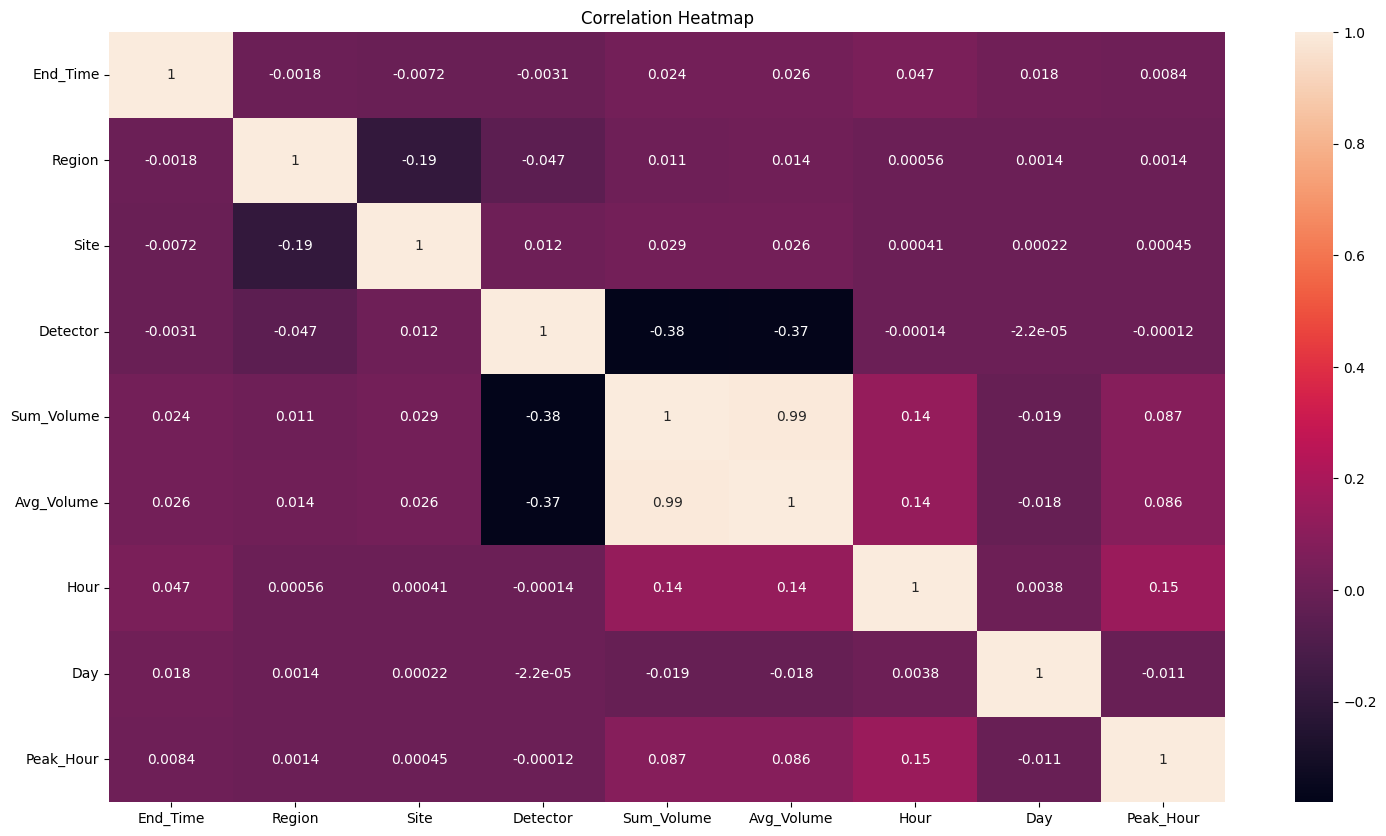

In [71]:
plt.figure(figsize=(18,10))
sns.heatmap(df_aug.corr(),annot=True)
plt.title('Correlation Heatmap')
plt.show()

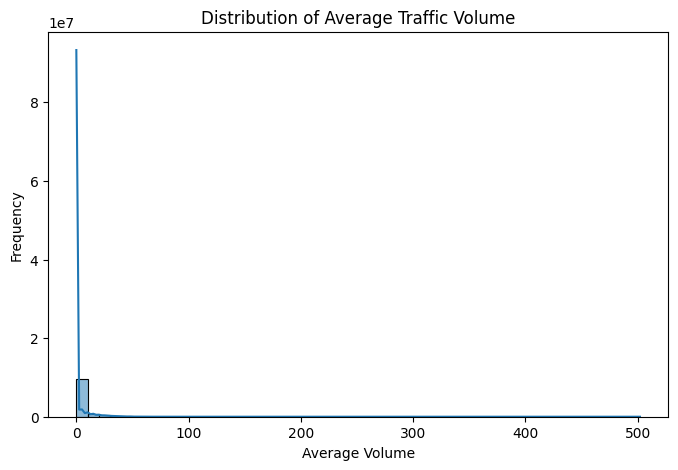

In [72]:
plt.figure(figsize=(8,5))
sns.histplot(df_aug['Avg_Volume'], bins=50, kde=True)
plt.title("Distribution of Average Traffic Volume")
plt.xlabel("Average Volume")
plt.ylabel("Frequency")
plt.show()

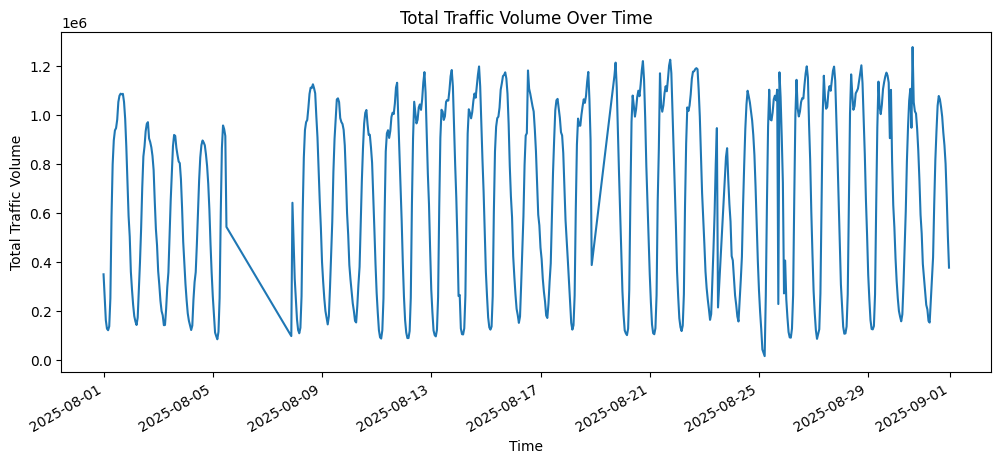

In [73]:
plt.figure(figsize=(12,5))
df_aug.groupby('End_Time')['Sum_Volume'].sum().plot()
plt.title("Total Traffic Volume Over Time")
plt.xlabel("Time")
plt.ylabel("Total Traffic Volume")
plt.show()

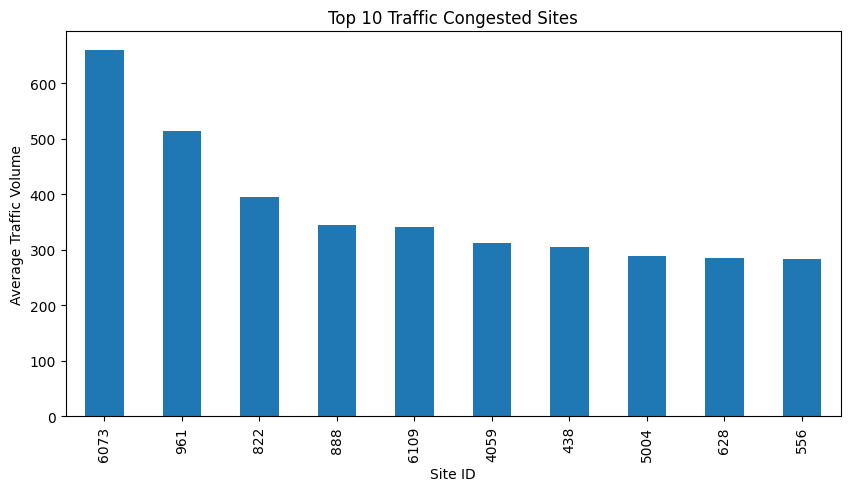

In [74]:
top_sites = (
    df_aug.groupby('Site')['Sum_Volume']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
top_sites.plot(kind='bar')
plt.title("Top 10 Traffic Congested Sites")
plt.xlabel("Site ID")
plt.ylabel("Average Traffic Volume")
plt.show()

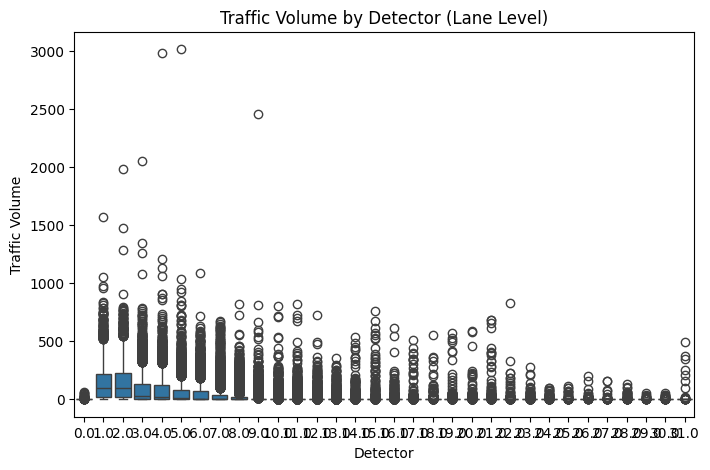

In [75]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x='Detector',
    y='Sum_Volume',
    data=df_aug.sample(50000)  # sampling for speed
)
plt.title("Traffic Volume by Detector (Lane Level)")
plt.xlabel("Detector")
plt.ylabel("Traffic Volume")
plt.show()

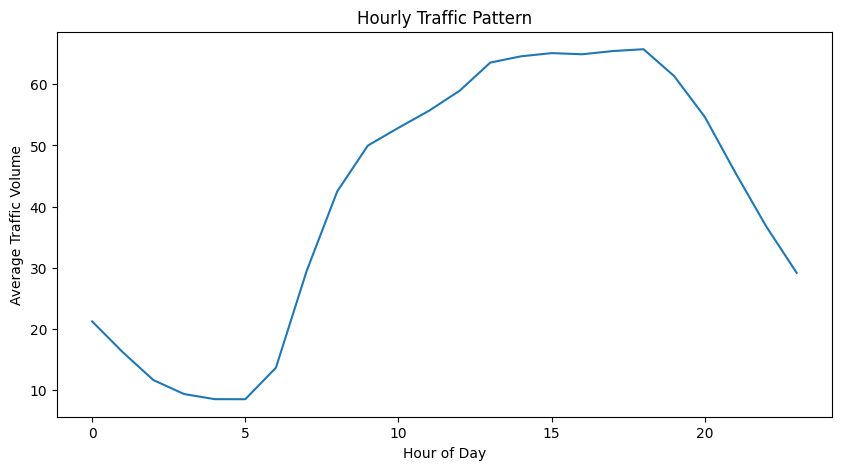

In [76]:
plt.figure(figsize=(10,5))
sns.lineplot(
    x='Hour',
    y='Sum_Volume',
    data=df_aug,
    estimator='mean',
    errorbar=None
)
plt.title("Hourly Traffic Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.show()

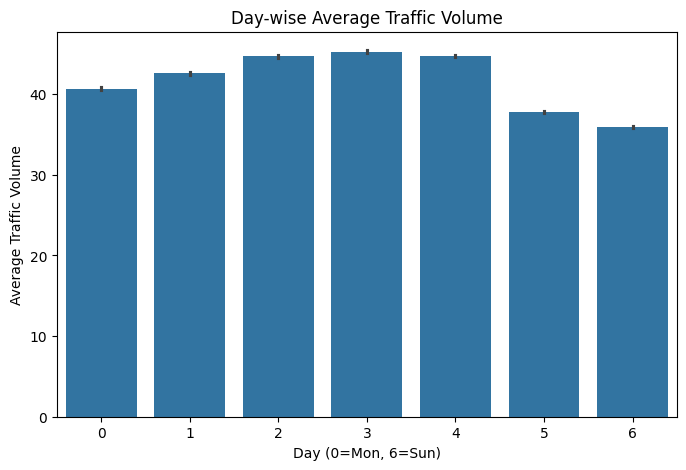

In [77]:
plt.figure(figsize=(8,5))
sns.barplot(
    x='Day',
    y='Sum_Volume',
    data=df_aug,
    estimator=np.mean
)
plt.title("Day-wise Average Traffic Volume")
plt.xlabel("Day (0=Mon, 6=Sun)")
plt.ylabel("Average Traffic Volume")
plt.show()

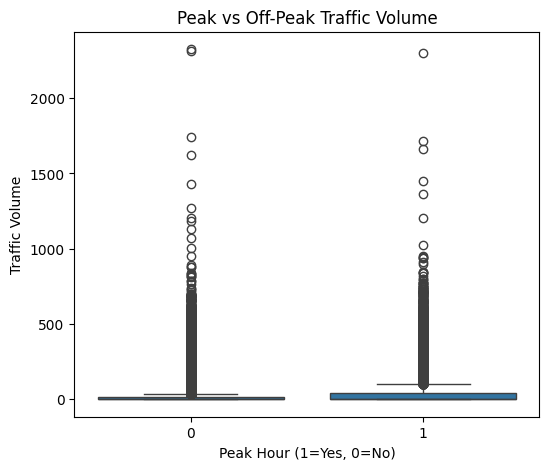

In [78]:
plt.figure(figsize=(6,5))
sns.boxplot(
    x='Peak_Hour',
    y='Sum_Volume',
    data=df_aug.sample(50000)
)
plt.title("Peak vs Off-Peak Traffic Volume")
plt.xlabel("Peak Hour (1=Yes, 0=No)")
plt.ylabel("Traffic Volume")
plt.show()

# **Train–Test Split**

In [79]:
features = [
    'Region',
    'Site',
    'Detector',
    'Hour',
    'Day',
    'Peak_Hour',
    'Avg_Volume'
]

X = df_aug[features]
y = df_aug['Sum_Volume']

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [81]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **Random Forest Model**

In [82]:
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

RandomForestRegressor(max_depth=15, n_estimators=50, n_jobs=-1, random_state=42)

# **Model Evaluation**

In [83]:
y_pred = rf_model.predict(X_test_scaled)

In [84]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 1.522119103276968
Root Mean Squared Error (RMSE): 7.323970660284035
R2 Score: 0.9949498679740781


# **Actual vs Predicted Visualization**

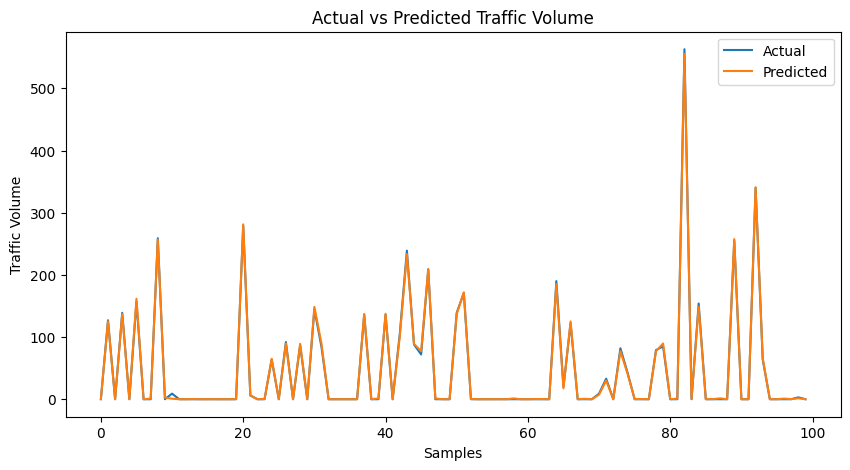

In [85]:
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:100], label='Actual')
plt.plot(y_pred[:100], label='Predicted')
plt.legend()
plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Samples")
plt.ylabel("Traffic Volume")
plt.show()

# **Congestion Level Classification**

In [ ]:
X_full_scaled = scaler.transform(X)
df_aug['RF_Predicted_Traffic'] = rf_model.predict(X_full_scaled)


In [87]:
# SAVE RANDOM FOREST MODEL

joblib.dump(rf_model, f"{BASE_PATH}/MACHINE_LEARNING/model.pkl")
joblib.dump(le, f"{BASE_PATH}/MACHINE_LEARNING/label_encoder.pkl")
joblib.dump(scaler, f"{BASE_PATH}/MACHINE_LEARNING/scaler.pkl")
print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [88]:
def predict_traffic(region, site, detector, hour, day, peak_hour, avg_volume):

    # Load saved model
    model = joblib.load(f"{BASE_PATH}/MACHINE_LEARNING/model.pkl")

    # Load scaler
    scaler = joblib.load(f"{BASE_PATH}/MACHINE_LEARNING/scaler.pkl")

    # Load label encoder
    label_encoder = joblib.load(f"{BASE_PATH}/MACHINE_LEARNING/label_encoder.pkl")

    # Encode region
    region_encoded = label_encoder.transform([region])[0]

    # Create input dataframe
    input_data = pd.DataFrame({
        'Region':[region_encoded],
        'Site':[site],
        'Detector':[detector],
        'Hour':[hour],
        'Day':[day],
        'Peak_Hour':[peak_hour],
        'Avg_Volume':[avg_volume]
    })

    # Scale input
    input_scaled = scaler.transform(input_data)

    # Predict
    predicted_volume = model.predict(input_scaled)[0]

    print("Predicted Traffic Volume:", predicted_volume)

    return predicted_volume

In [89]:
# TEST WITH USER INPUT

predict_traffic(
    region="SCITY",
    site=1009,
    detector=11,
    hour=8,
    day=1,
    peak_hour=1,
    avg_volume=4
)

Predicted Traffic Volume: 53.253723909219424


np.float64(53.253723909219424)

# **Time-Series Aggregation**

In [90]:
# choose most active site
site_id = df_aug['Site'].value_counts().idxmax()

df_site = df_aug[df_aug['Site'] == site_id]

ts = (
    df_site
    .set_index('End_Time')
    .resample('h')['Sum_Volume']
    .mean()
    .dropna()
)

print("Time series length:", len(ts))

Time series length: 659


# **Scaling**

In [91]:
scaler_ts = MinMaxScaler()
ts_scaled = scaler_ts.fit_transform(ts.values.reshape(-1,1))

# **Create Time Sequences**

In [92]:
def create_sequences(series, window):

    X = []
    y = []

    for i in range(len(series) - window):
        X.append(series[i:i+window])
        y.append(series[i+window])

    return np.array(X), np.array(y)

WINDOW = 48   # 48 hours history (better learning)

X_seq, y_seq = create_sequences(ts_scaled, WINDOW)

print("Sequence shape:", X_seq.shape)

Sequence shape: (611, 48, 1)


# **Train-Test Split**

In [93]:
split = int(len(X_seq) * 0.8)

X_train_gru = X_seq[:split]
X_test_gru  = X_seq[split:]

y_train_gru = y_seq[:split]
y_test_gru  = y_seq[split:]

# **GRU Model**

In [95]:
gru_model = tf.keras.Sequential()

gru_model.add(tf.keras.layers.Input(shape=(WINDOW,1)))

gru_model.add(tf.keras.layers.GRU(64, return_sequences=True))
gru_model.add(tf.keras.layers.GRU(32))

gru_model.add(tf.keras.layers.Dense(16, activation='relu'))
gru_model.add(tf.keras.layers.Dense(1))

gru_model.compile(
    optimizer='adam',
    loss='mse'
)

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 48, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

In [97]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [98]:
history = gru_model.fit(
    X_train_gru,
    y_train_gru,
    epochs=40,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.1814 - val_loss: 0.0566
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0467 - val_loss: 0.0483
Epoch 3/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0371 - val_loss: 0.0381
Epoch 4/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0268 - val_loss: 0.0308
Epoch 5/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0249 - val_loss: 0.0246
Epoch 6/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0181 - val_loss: 0.0201
Epoch 7/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0130 - val_loss: 0.0181
Epoch 8/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0135 - val_loss: 0.0165
Epoch 9/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0120 - val_loss: 0.0163
Epoch 10/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0105 - val_loss: 0.0148
Epoch 11/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0109 - val_loss: 0.0138
Epoch 12/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0108 - va

# **Evaluate GRU**

In [99]:
y_pred_gru_scaled = gru_model.predict(X_test_gru)

y_pred_gru = scaler_ts.inverse_transform(y_pred_gru_scaled)

y_test_actual = scaler_ts.inverse_transform(y_test_gru)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


In [100]:
mae_gru = mean_absolute_error(y_test_actual, y_pred_gru)
rmse_gru = np.sqrt(mean_squared_error(y_test_actual, y_pred_gru))
r2_gru = r2_score(y_test_actual, y_pred_gru)

print("GRU MAE :", mae_gru)
print("GRU RMSE:", rmse_gru)
print("R2 Score:", r2_gru)

GRU MAE : 2.8632116637578826
GRU RMSE: 3.9025797510938363
R2 Score: 0.9446838395094952


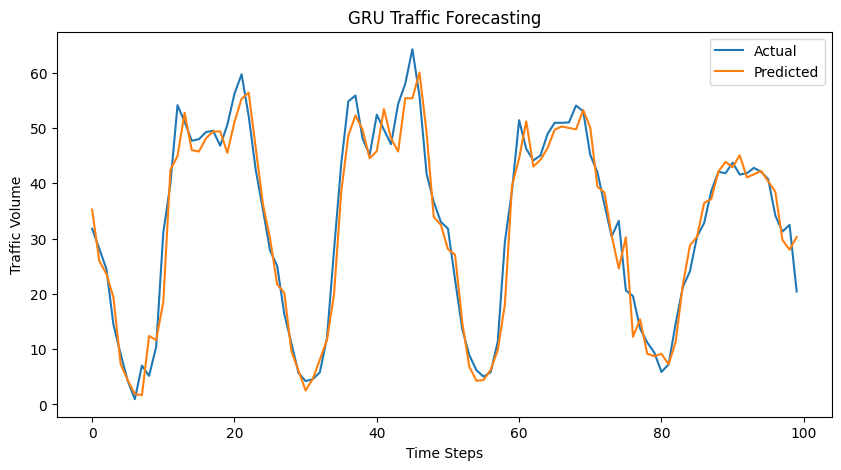

In [101]:
plt.figure(figsize=(10,5))

plt.plot(y_test_actual[:100], label='Actual')
plt.plot(y_pred_gru[:100], label='Predicted')

plt.title("GRU Traffic Forecasting")
plt.xlabel("Time Steps")
plt.ylabel("Traffic Volume")

plt.legend()
plt.show()

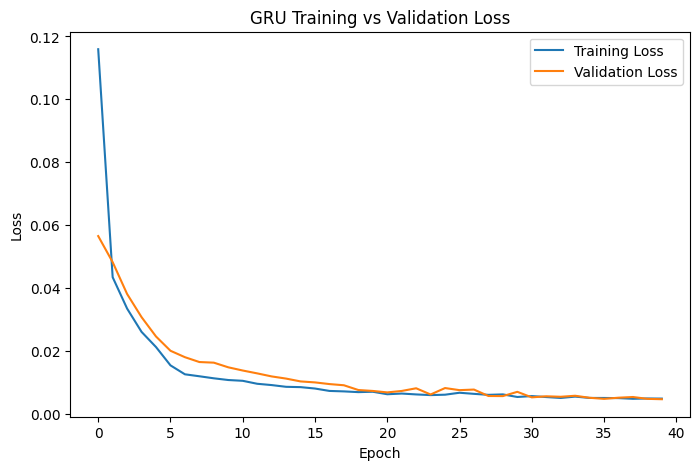

In [102]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("GRU Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [103]:
print("Random Forest MAE :", mae)
print("Random Forest RMSE:", rmse)

print("\nGRU MAE :", mae_gru)
print("GRU RMSE:", rmse_gru)

Random Forest MAE : 1.522119103276968
Random Forest RMSE: 7.323970660284035

GRU MAE : 2.8632116637578826
GRU RMSE: 3.9025797510938363


In [ ]:

# CREATE OUTPUT CSV
rf_output = pd.DataFrame({

    'Date Time': df_aug['End_Time'],
    
    'Region': df_aug['Region'],

    'Site name': df_aug['Site'],

    'Detector': df_aug['Detector'],

    'Hour': df_aug['Hour'],

    'Day': df_aug['Day'],

    'Peak_Hour': df_aug['Peak_Hour'],

    'Average Traffic_Volume': df_aug['Avg_Volume'],

    'Actual': df_aug['Sum_Volume'],

    'Predicted Congestion': (
        df_aug['RF_Predicted_Traffic'].round(8)
    )

})

# SAVE CSV
rf_output['Date Time'] = rf_output['Date Time'].astype(str)
rf_output.to_csv(
    f"{BASE_PATH}/MACHINE_LEARNING/data.csv",
    index=False
)

print("data.csv saved successfully!")

data.csv saved successfully!
